# Predicting Agricultural Productivity Levels in Rwanda

**Dataset:** Rwanda Seasonal Agricultural Survey 2025 (SAS 2025)  
**Task:** Multi-class classification

## 1. Introduction

In this project, I used agricultural survey data from Rwanda to group farming plots into low, medium, and high productivity levels. First, I prepared and cleaned the data. Then, I trained different machine learning models, built a neural network model, and compared their performance.

The productivity groups were created from the Yield column using the lower and upper tertiles. These groups were created based on the data and are not the official productivity categories used by NISR. The results help us understand patterns in the data, but they should not be used as direct recommendations for individual farmers.

## 2. Importing Libraries

I used pandas and NumPy to work with the data, scikit-learn for traditional machine learning, and TensorFlow/Keras for the deep learning model. I also used plots and evaluation metrics to compare the models.

In [1]:
import os
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, precision_recall_fscore_support,
    roc_auc_score, RocCurveDisplay
)

warnings.filterwarnings("ignore", category=FutureWarning)
np.random.seed(42)
tf.random.set_seed(42)

print("Libraries imported successfully.")
print("TensorFlow version:", tf.__version__)
print("Pandas version:", pd.__version__)

Libraries imported successfully.
TensorFlow version: 2.21.0
Pandas version: 2.2.3


## 3. Loading the Dataset

The dataset is provided as a ZIP file. I uploaded the ZIP file, found the Season A 2025 production file, and loaded it into a pandas DataFrame. Since the file is tab-separated, I used **sep="\t"** when reading it.

In [2]:
# Upload Microdata.zip from my computer in Google Colab
from google.colab import files

uploaded = files.upload()

zip_files = [name for name in uploaded.keys() if name.lower().endswith(".zip")]
if not zip_files:
    raise FileNotFoundError("Please upload the Microdata.zip file.")

zip_path = zip_files[0]
print("Uploaded file:", zip_path)

target_suffix = "Rwa_raw_SeasonA2025_Production.csv"

with zipfile.ZipFile(zip_path, "r") as archive:
    matches = [name for name in archive.namelist() if name.endswith(target_suffix)]
    if not matches:
        raise FileNotFoundError(
            "Could not find the Season A 2025 production file in the ZIP archive."
        )

    production_path_in_zip = matches[0]
    archive.extract(production_path_in_zip, "/content")

csv_path = os.path.join("/content", production_path_in_zip)
df = pd.read_csv(csv_path, sep="\t", low_memory=False)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
display(df.head())

Saving Microdata.zip to Microdata.zip
Uploaded file: Microdata.zip
Dataset loaded successfully.
Dataset shape: (34369, 101)


,Segment_ID,s1q1,s1q2,s1q3,s1q4,s1q6,s1q7,s1q8,s1q9,s1q14,...,s4q8,s4q9,s4q13,s4q14,Plot_area_ha,Harvest_ratio,Crop_Area_ha,Harvested_Crop_Area_ha,Yield,plot_weight
0,12001,Kigali,Gasabo,LSF,1,1,Large scale farmer as individual,Male,64.0,No,...,Yes,Yes,Yes,Yes,27.844120,100.0,26.173480,26.173480,17651.5400,1.0
1,12001,Kigali,Gasabo,LSF,1,1,Large scale farmer as individual,Male,64.0,No,...,Yes,Yes,Yes,No,8.043123,100.0,7.640967,7.640967,331.5026,1.0
2,12001,Kigali,Gasabo,LSF,1,1,Large scale farmer as individual,Male,64.0,No,...,Yes,Yes,Yes,No,10.944560,100.0,10.725670,10.725670,29805.1300,1.0
3,12001,Kigali,Gasabo,LSF,1,1,Large scale farmer as individual,Male,64.0,No,...,Yes,Yes,Yes,No,0.651637,100.0,0.586473,0.586473,8459.0360,1.0
4,12001,Kigali,Gasabo,LSF,1,1,Large scale farmer as individual,Male,64.0,No,...,Yes,Yes,Yes,No,1.259719,100.0,1.259719,1.259719,8460.6200,1.0


## 4. Understanding the Dataset

I checked the column names, data types, and missing values before preparing the data. This helped me understand what information is available and what may need cleaning.

In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-missing values:")
df.info()

missing_values = df.isna().sum().sort_values(ascending=False)
missing_values = missing_values[missing_values > 0]

print("\nColumns with missing values:")
display(missing_values.to_frame("missing_count").head(20))

Number of rows: 34369
Number of columns: 101

Column names:
['Segment_ID', 's1q1', 's1q2', 's1q3', 's1q4', 's1q6', 's1q7', 's1q8', 's1q9', 's1q14', 's1q16', 's2q1', 's2q2', 's2q3', 's2q4', 'CropCategory', 's2q4_o', 's2q5', 's2q6', 's2q7', 's2q8', 's2q9', 's2q10', 's2q10_Other', 's2q11', 's2q12', 's2q13_1', 's2q13_2', 's2q14', 's2q15_a', 's2q15_b', 's2q16_1', 's2q16_2', 's2q17', 's2q18_a', 's2q18_b', 's2q19_1', 's2q19_2', 's2q19_3', 's2q20_1', 's2q20_2', 's2q21', 's2q22', 's2q23', 's2q24_e1', 's2q24_e2', 's2q24_e3', 's2q24_d', 's2q25', 's2q25_food', 's2q25_drink', 's2q25_other', 's2q26', 's2q27', 's2q27_Other_place', 's2q28', 's2q29', 's2q30', 's2q31', 's2q32', 's2q33', 's2q34', 's2q35', 's2q36', 's2q37', 's2q37_Other_storage', 's2q37_public', 's2q38', 's2q41', 's2q42', 's2q43', 's2q44', 's2q45', 's2q46', 's2q47', 's2q48', 's2q49', 's2q50', 's3q1', 's3q3', 's3q7', 's3q9', 's3q16', 's3q17', 's3q18', 's3q19', 's4q1', 's4q2', 's4q3', 's4q4', 's4q6', 's4q8', 's4q9', 's4q13', 's4q14', 'Plot_

,missing_count
s2q37_Other_storage,34357
s2q27_Other_place,34342
s2q4_o,34293
s2q10_Other,34278
s2q18_b,34165
s4q9,33874
s3q17,33691
s2q37,32736
s2q24_e3,32660
s2q24_d,32216


## 5. Exploring Important Variables

I explored the main variables that may affect agricultural productivity. I also checked the distribution of the Yield column and looked for any unusual values. Since the productivity groups are based on Yield, the values need to be positive so that the groups are meaningful for this project.

,s1q1,s1q2,s1q3,s1q7,s1q8,s1q9,CropCategory,Plot_area_ha,Crop_Area_ha,Harvested_Crop_Area_ha,Yield
0,Kigali,Gasabo,LSF,Large scale farmer as individual,Male,64.0,Fodder crops,27.844120,26.173480,26.173480,17651.5400
1,Kigali,Gasabo,LSF,Large scale farmer as individual,Male,64.0,Fodder crops,8.043123,7.640967,7.640967,331.5026
2,Kigali,Gasabo,LSF,Large scale farmer as individual,Male,64.0,Fodder crops,10.944560,10.725670,10.725670,29805.1300
3,Kigali,Gasabo,LSF,Large scale farmer as individual,Male,64.0,Fodder crops,0.651637,0.586473,0.586473,8459.0360
4,Kigali,Gasabo,LSF,Large scale farmer as individual,Male,64.0,Fodder crops,1.259719,1.259719,1.259719,8460.6200


Yield summary:


,Yield
count,29938.000000
mean,5019.822458
std,7254.313315
min,6.693367
25%,674.703750
50%,1948.042500
75%,9014.638750
max,528854.700000


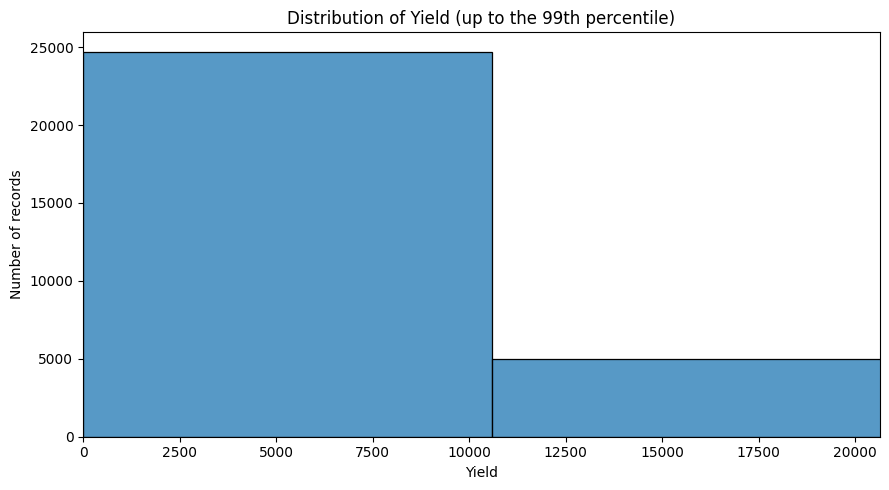

In [4]:
important_columns = [
    "s1q1", "s1q2", "s1q3", "s1q7", "s1q8", "s1q9",
    "CropCategory", "Plot_area_ha", "Crop_Area_ha",
    "Harvested_Crop_Area_ha", "Yield"
]

available_columns = [col for col in important_columns if col in df.columns]
display(df[available_columns].head())

if "Yield" not in df.columns:
    raise KeyError("The dataset does not contain the expected 'Yield' column.")

df["Yield"] = pd.to_numeric(df["Yield"], errors="coerce")

print("Yield summary:")
display(df["Yield"].describe().to_frame())

plt.figure(figsize=(9, 5))
sns.histplot(df["Yield"].dropna(), bins=50)
plt.xlim(0, df["Yield"].quantile(0.99))
plt.title("Distribution of Yield (up to the 99th percentile)")
plt.xlabel("Yield")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

## 6. Defining the Classification Problem

The original Yield variable contains numerical values, so I converted it into three classes: Low, Medium, and High. I used the 33rd and 67th percentiles as the cut-off points to create three groups with roughly the same number of samples.

To avoid data leakage, I did not use the Yield column when training the models. I also excluded Harvested_Crop_Area_ha because it may include information collected after harvesting. Instead, I used the other selected features related to the plot, crop, and farmer.

Rows in raw dataset: 34369
Rows with valid positive yield: 29938
Low/Medium cut-off: 920.112
Medium/High cut-off: 6590.546

Class counts:


,count
productivity_class,
Low,9979
Medium,9979
High,9980


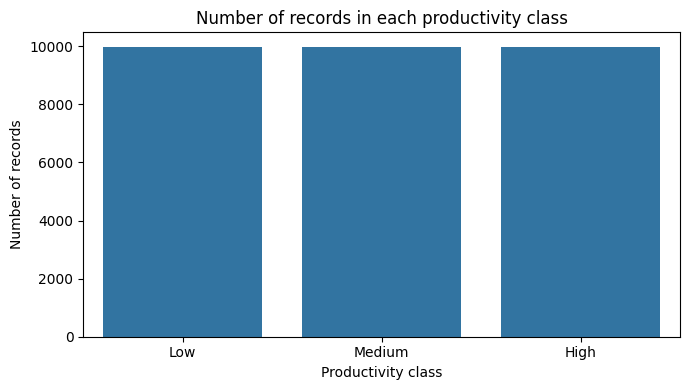

In [5]:
# Keep rows with a valid, positive yield
work_df = df.copy()
work_df["Yield"] = pd.to_numeric(work_df["Yield"], errors="coerce")
work_df = work_df.loc[work_df["Yield"].notna() & (work_df["Yield"] > 0)].copy()

# Create three yield groups using tertiles
lower_cutoff = work_df["Yield"].quantile(1 / 3)
upper_cutoff = work_df["Yield"].quantile(2 / 3)

work_df["productivity_class"] = pd.cut(
    work_df["Yield"],
    bins=[-np.inf, lower_cutoff, upper_cutoff, np.inf],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

print("Rows in raw dataset:", len(df))
print("Rows with valid positive yield:", len(work_df))
print(f"Low/Medium cut-off: {lower_cutoff:.3f}")
print(f"Medium/High cut-off: {upper_cutoff:.3f}")

print("\nClass counts:")
display(work_df["productivity_class"].value_counts().reindex(["Low", "Medium", "High"]).to_frame("count"))

plt.figure(figsize=(7, 4))
sns.countplot(data=work_df, x="productivity_class", order=["Low", "Medium", "High"])
plt.title("Number of records in each productivity class")
plt.xlabel("Productivity class")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

## 7. Selecting Features and Preparing the Data

I used location, crop category, farmer characteristics, and plot area as the input features. I did not include the target variable, Yield, or Harvested_Crop_Area_ha because it may contain information collected after harvesting.

Before training the models, I split the data into training and testing sets. I filled missing numerical values with the median and missing categorical values with the most common value. I also converted the categorical variables into numbers using one-hot encoding.

In [6]:
categorical_features = [
    col for col in ["s1q1", "s1q2", "s1q3", "s1q7", "s1q8", "CropCategory"]
    if col in work_df.columns
]
numeric_features = [
    col for col in ["s1q9", "Plot_area_ha", "Crop_Area_ha"]
    if col in work_df.columns
]

feature_columns = categorical_features + numeric_features
if not feature_columns:
    raise ValueError("No expected feature columns were found in the dataset.")

X = work_df[feature_columns].copy()
y = work_df["productivity_class"].astype(str)

# Convert numeric features to numeric values where possible
for col in numeric_features:
    X[col] = pd.to_numeric(X[col], errors="coerce")

# Convert category values to strings to make encoding consistent
for col in categorical_features:
    X[col] = X[col].where(X[col].notna(), np.nan).astype("object")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train).astype("float32")
X_test_processed = preprocessor.transform(X_test).astype("float32")

class_names = ["Low", "Medium", "High"]
class_to_number = {name: index for index, name in enumerate(class_names)}
y_train_encoded = y_train.map(class_to_number).to_numpy(dtype="int32")
y_test_encoded = y_test.map(class_to_number).to_numpy(dtype="int32")

print("Feature columns:", feature_columns)
print("Training rows:", X_train_processed.shape[0])
print("Testing rows:", X_test_processed.shape[0])
print("Processed feature count:", X_train_processed.shape[1])
print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).reindex(class_names).round(3))
print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).reindex(class_names).round(3))

Feature columns: ['s1q1', 's1q2', 's1q3', 's1q7', 's1q8', 'CropCategory', 's1q9', 'Plot_area_ha', 'Crop_Area_ha']
Training rows: 23950
Testing rows: 5988
Processed feature count: 70

Training class distribution:
productivity_class
Low       0.333
Medium    0.333
High      0.333
Name: proportion, dtype: float64

Testing class distribution:
productivity_class
Low       0.333
Medium    0.333
High      0.333
Name: proportion, dtype: float64


## 8. Traditional Machine Learning Models

I used three traditional machine learning models: Logistic Regression, Random Forest, and Gradient Boosting. I trained all the models using the same training data and evaluated their performance on the test set using accuracy, precision, recall, and F1-score.

In [7]:
traditional_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42, class_weight="balanced", n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

traditional_results = []
trained_models = {}

for model_name, model in traditional_models.items():
    print(f"Training {model_name}")
    model.fit(X_train_processed, y_train)
    predictions = model.predict(X_test_processed)

    traditional_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision_recall_fscore_support(
            y_test, predictions, average="macro", zero_division=0
        )[0],
        "Macro Recall": precision_recall_fscore_support(
            y_test, predictions, average="macro", zero_division=0
        )[1],
        "Macro F1": precision_recall_fscore_support(
            y_test, predictions, average="macro", zero_division=0
        )[2]
    })
    trained_models[model_name] = model

traditional_results_df = pd.DataFrame(traditional_results).sort_values(
    "Macro F1", ascending=False
).reset_index(drop=True)

display(traditional_results_df.round(4))

Training Logistic Regression
Training Random Forest
Training Gradient Boosting


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Logistic Regression,0.7968,0.7930,0.7968,0.7942
1,Gradient Boosting,0.7963,0.7916,0.7963,0.7923
2,Random Forest,0.7929,0.7895,0.7929,0.7908


## 9. Evaluating the Traditional Models

I evaluated the performance of each model using accuracy, precision, recall, and F1-score. I also used the classification report and confusion matrix to compare the models and understand their prediction errors.



Logistic Regression
              precision    recall  f1-score   support

         Low       0.79      0.78      0.79      1996
      Medium       0.71      0.67      0.69      1996
        High       0.87      0.94      0.91      1996

    accuracy                           0.80      5988
   macro avg       0.79      0.80      0.79      5988
weighted avg       0.79      0.80      0.79      5988



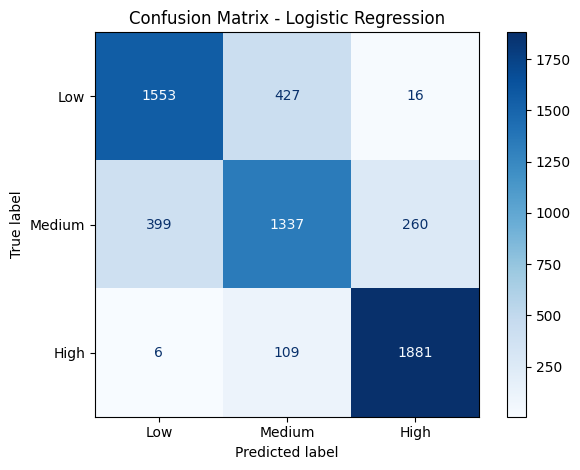



Random Forest
              precision    recall  f1-score   support

         Low       0.77      0.78      0.78      1996
      Medium       0.70      0.66      0.68      1996
        High       0.89      0.94      0.91      1996

    accuracy                           0.79      5988
   macro avg       0.79      0.79      0.79      5988
weighted avg       0.79      0.79      0.79      5988



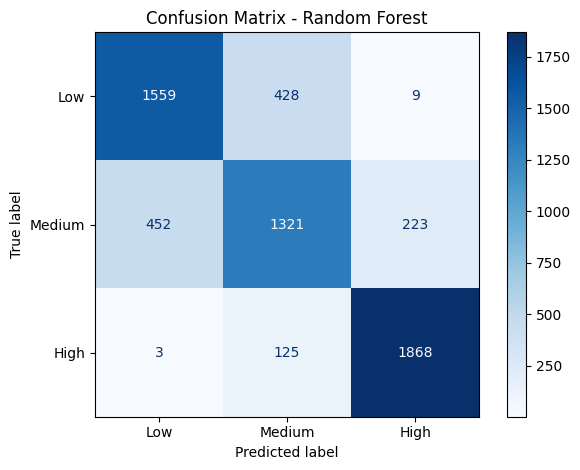



Gradient Boosting
              precision    recall  f1-score   support

         Low       0.80      0.77      0.79      1996
      Medium       0.72      0.65      0.69      1996
        High       0.85      0.96      0.90      1996

    accuracy                           0.80      5988
   macro avg       0.79      0.80      0.79      5988
weighted avg       0.79      0.80      0.79      5988



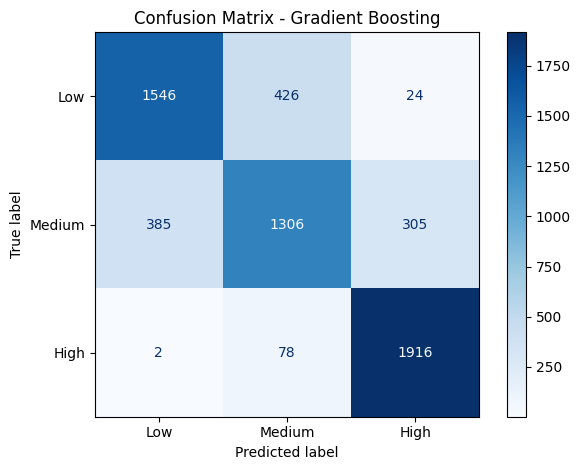

In [8]:
for model_name, model in trained_models.items():
    predictions = model.predict(X_test_processed)

    print("\n")
    print(model_name)
    print(classification_report(
        y_test, predictions,
        labels=class_names, zero_division=0
    ))

    cm = confusion_matrix(y_test, predictions, labels=class_names)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    plt.show()

## 10. Hyperparameter Tuning

I adjusted some Random Forest settings to improve the model performance. I used cross-validation with the training data only, while keeping the test set separate for the final evaluation.

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 3, 'classifier__n_estimators': 100}
Best cross-validation macro F1: 0.7987
Tuned Random Forest test accuracy: 0.8014

Classification report for tuned Random Forest:
              precision    recall  f1-score   support

         Low       0.79      0.79      0.79      1996
      Medium       0.72      0.66      0.69      1996
        High       0.88      0.95      0.91      1996

    accuracy                           0.80      5988
   macro avg       0.80      0.80      0.80      5988
weighted avg       0.80      0.80      0.80      5988



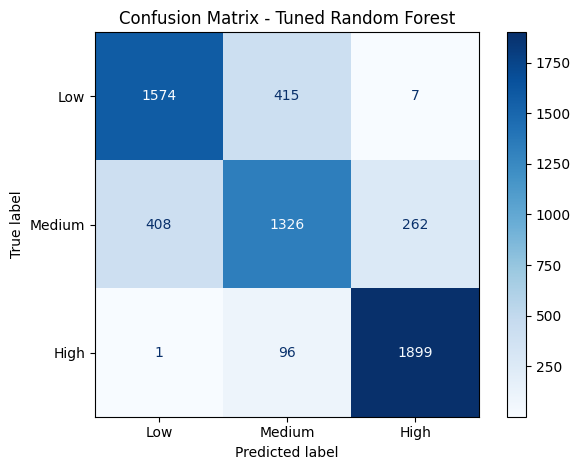

In [9]:
# Tune the Random Forest model
rf_for_tuning = RandomForestClassifier(
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# Put preprocessing and Random Forest in one pipeline
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", rf_for_tuning)
])

param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 15],
    "classifier__min_samples_leaf": [1, 3]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1,
    verbose=1
)

# Use the original training data for cross-validation
grid_search.fit(X_train, y_train)

# Keep the pipeline for predictions on the original features
best_rf_pipeline = grid_search.best_estimator_

# Keep the Random Forest model itself for the other notebook sections
best_rf = best_rf_pipeline.named_steps["classifier"]

tuned_predictions = best_rf_pipeline.predict(X_test)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation macro F1:", round(grid_search.best_score_, 4))
print("Tuned Random Forest test accuracy:", round(accuracy_score(y_test, tuned_predictions), 4))
print("\nClassification report for tuned Random Forest:")
print(classification_report(
    y_test, tuned_predictions,
    labels=class_names,
    zero_division=0
))

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(
        y_test, tuned_predictions, labels=class_names
    ),
    display_labels=class_names
).plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix - Tuned Random Forest")
plt.tight_layout()
plt.show()

trained_models["Tuned Random Forest"] = best_rf

## 11. Deep Learning with TensorFlow/Keras

I built a feed-forward neural network to predict the three productivity classes. The data was prepared and provided to the model using TensorFlow/Keras. I used a validation set to monitor the training process and applied early stopping to prevent overtraining.

In [10]:
# Create a validation set from the training data
X_dl_train, X_dl_val, y_dl_train, y_dl_val = train_test_split(
    X_train_processed,
    y_train_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_train_encoded
)

batch_size = 64

train_ds = tf.data.Dataset.from_tensor_slices((X_dl_train, y_dl_train))
train_ds = train_ds.shuffle(
    buffer_size=len(X_dl_train), seed=42, reshuffle_each_iteration=True
).batch(batch_size).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices((X_dl_val, y_dl_val))
val_ds = val_ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test_processed, y_test_encoded)
).batch(batch_size).prefetch(tf.data.AUTOTUNE)

def build_model(input_size, learning_rate=0.001, dropout_rate=0.2):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_size,)),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.Dense(3, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

dl_model = build_model(
    input_size=X_train_processed.shape[1],
    learning_rate=0.001,
    dropout_rate=0.2
)

dl_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         4,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,723 (26.26 KB)

 Trainable params: 6,723 (26.26 KB)

 Non-trainable params: 0 (0.00 B)

## 12. Training the Neural Network

I trained the neural network for up to 40 epochs. I used early stopping to stop the training when the validation loss stopped improving and kept the best model weights.

In [11]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = dl_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/40
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6777 - loss: 0.7110 - val_accuracy: 0.7935 - val_loss: 0.4640
Epoch 2/40
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7857 - loss: 0.4856 - val_accuracy: 0.7971 - val_loss: 0.4520
Epoch 3/40
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7908 - loss: 0.4692 - val_accuracy: 0.7998 - val_loss: 0.4436
Epoch 4/40
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7967 - loss: 0.4593 - val_accuracy: 0.7987 - val_loss: 0.4416
Epoch 5/40
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7976 - loss: 0.4496 - val_accuracy: 0.8010 - val_loss: 0.4381
Epoch 6/40
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7996 - loss: 0.4460 - val_accuracy: 0.8023 - val_loss: 0.4362
Epoch 7/40
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8012 - loss: 0.4407 - val_accuracy: 0.8027 - val_loss: 0.4326
Epoch 8/40
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8008 - loss: 0.4396 - val_accuracy: 0.

## 13. Looking at the Learning Curves

I used learning curves to observe how the model’s accuracy and loss changed during training. These curves helped me check if the model was overfitting by comparing the training and validation performance.

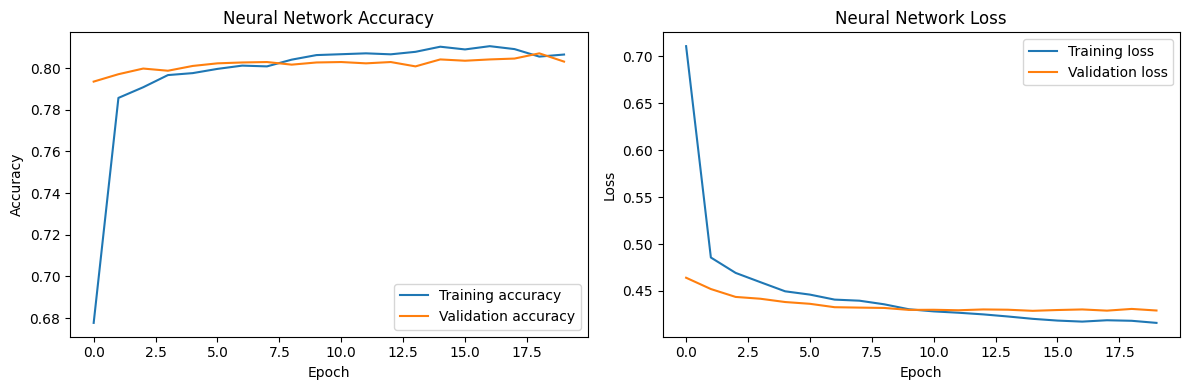

In [12]:
history_df = pd.DataFrame(history.history)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_df["accuracy"], label="Training accuracy")
plt.plot(history_df["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Neural Network Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_df["loss"], label="Training loss")
plt.plot(history_df["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Neural Network Loss")
plt.legend()

plt.tight_layout()
plt.show()

## 14. First Neural Network Experiment

I trained the first neural network using the training data and monitored its performance on the validation data. I used early stopping to help prevent overfitting. Its performance was later compared with a second neural network experiment.

Neural Network Test Accuracy: 0.8048

Classification report:
              precision    recall  f1-score   support

         Low       0.81      0.77      0.79      1996
      Medium       0.72      0.68      0.70      1996
        High       0.87      0.96      0.91      1996

    accuracy                           0.80      5988
   macro avg       0.80      0.80      0.80      5988
weighted avg       0.80      0.80      0.80      5988



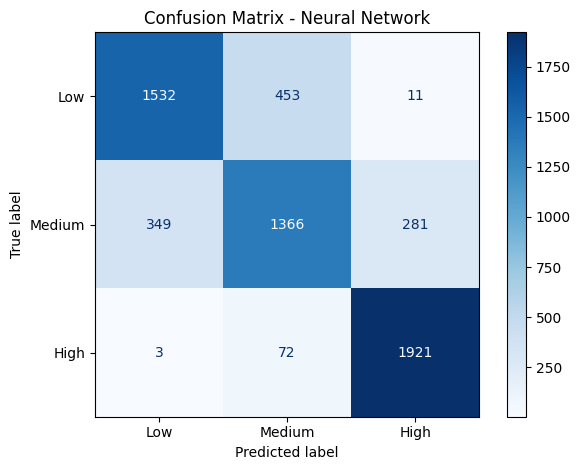

In [13]:
dl_probabilities = dl_model.predict(test_ds, verbose=0)
dl_predictions_encoded = np.argmax(dl_probabilities, axis=1)
dl_predictions = np.array(class_names)[dl_predictions_encoded]

print("Neural Network Test Accuracy:", round(
    accuracy_score(y_test, dl_predictions), 4
))
print("\nClassification report:")
print(classification_report(
    y_test, dl_predictions,
    labels=class_names, zero_division=0
))

cm_dl = confusion_matrix(y_test, dl_predictions, labels=class_names)
ConfusionMatrixDisplay(
    confusion_matrix=cm_dl, display_labels=class_names
).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Neural Network")
plt.tight_layout()
plt.show()

# Save the first model and its training history
dl_model_1 = dl_model
history_1 = history

### Second Neural Network Experiment

I trained a second neural network using a lower learning rate of 0.0005 and a dropout rate of 0.3. I compared it with the first neural network to see whether these changes improved the model's performance. I used macro F1-score and accuracy to compare the results.

In [14]:
# Second neural network configuration
dl_model_2 = build_model(
    input_size=X_train_processed.shape[1],
    learning_rate=0.0005,
    dropout_rate=0.3
)

early_stopping_2 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_2 = dl_model_2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=[early_stopping_2],
    verbose=1
)

Epoch 1/40
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5971 - loss: 0.8923 - val_accuracy: 0.7808 - val_loss: 0.5693
Epoch 2/40
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7533 - loss: 0.5835 - val_accuracy: 0.7962 - val_loss: 0.4748
Epoch 3/40
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7720 - loss: 0.5209 - val_accuracy: 0.7996 - val_loss: 0.4604
Epoch 4/40
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7813 - loss: 0.4975 - val_accuracy: 0.8038 - val_loss: 0.4512
Epoch 5/40
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7878 - loss: 0.4837 - val_accuracy: 0.7996 - val_loss: 0.4500
Epoch 6/40
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7914 - loss: 0.4758 - val_accuracy: 0.8015 - val_loss: 0.4452
Epoch 7/40
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7916 - loss: 0.4713 - val_accuracy: 0.8021 - val_loss: 0.4420
Epoch 8/40
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7944 - loss: 0.4639 - val_accuracy: 0.

### Comparing the Two Neural Network Experiments

I compared both neural networks using validation accuracy and macro F1-score. I selected the model with the higher macro F1-score and then evaluated it on the test set.

In [15]:
# Compare both neural networks on the validation set
neural_networks = {
    "Neural Network 1": dl_model_1,
    "Neural Network 2": dl_model_2
}

nn_results = []

for name, model in neural_networks.items():
    probabilities = model.predict(X_dl_val, verbose=0)
    predictions = np.argmax(probabilities, axis=1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_dl_val,
        predictions,
        average="macro",
        zero_division=0
    )

    nn_results.append({
        "Model": name,
        "Validation Accuracy": accuracy_score(
            y_dl_val, predictions
        ),
        "Validation Macro F1": f1
    })

nn_results_df = pd.DataFrame(nn_results).sort_values(
    "Validation Macro F1", ascending=False
).reset_index(drop=True)

display(nn_results_df.round(4))

# Select the model with the highest validation Macro F1
best_dl_name = nn_results_df.iloc[0]["Model"]
selected_model = neural_networks[best_dl_name]

print("Selected model:", best_dl_name)

,Model,Validation Accuracy,Validation Macro F1
0,Neural Network 2,0.8056,0.8017
1,Neural Network 1,0.8042,0.8007


Selected model: Neural Network 2


### Final Neural Network Evaluation (Test Set)

After selecting the best neural network using validation results, I evaluated it on the test set. I used accuracy, a classification report, and a confusion matrix to assess its performance.

Selected Neural Network: Neural Network 2
Test Accuracy: 0.8036

Classification Report:
              precision    recall  f1-score   support

         Low       0.80      0.79      0.79      1996
      Medium       0.73      0.67      0.70      1996
        High       0.87      0.96      0.91      1996

    accuracy                           0.80      5988
   macro avg       0.80      0.80      0.80      5988
weighted avg       0.80      0.80      0.80      5988



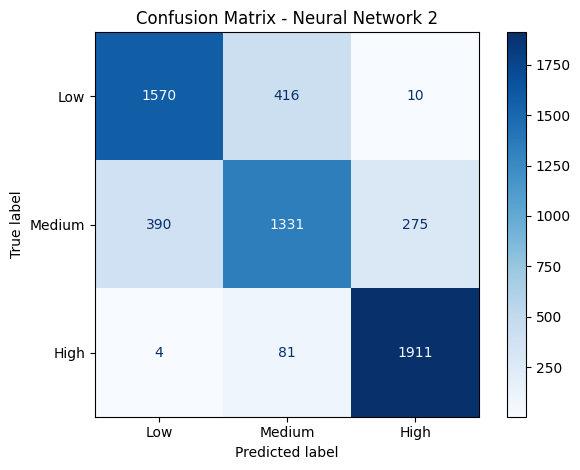

In [16]:
# Predict using the selected neural network
dl_probabilities = selected_model.predict(test_ds, verbose=0)

dl_predictions_encoded = np.argmax(dl_probabilities, axis=1)
dl_predictions = np.array(class_names)[dl_predictions_encoded]

# Evaluate the selected model
print("Selected Neural Network:", best_dl_name)
print("Test Accuracy:", round(
    accuracy_score(y_test, dl_predictions), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    dl_predictions,
    labels=class_names,
    zero_division=0
))

# Confusion matrix
cm_dl = confusion_matrix(
    y_test,
    dl_predictions,
    labels=class_names
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_dl,
    display_labels=class_names
).plot(cmap="Blues", values_format="d")

plt.title(f"Confusion Matrix - {best_dl_name}")
plt.tight_layout()
plt.show()

## 15. Comparing All Models

I compared the traditional machine learning models with the best neural network selected from the two experiments. I used test accuracy, macro precision, macro recall, and macro F1-score to compare their performance.

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Neural Network 2,0.8036,0.7992,0.8036,0.8003
1,Tuned Random Forest,0.8014,0.7972,0.8014,0.7984
2,Logistic Regression,0.7968,0.7930,0.7968,0.7942
3,Gradient Boosting,0.7963,0.7916,0.7963,0.7923
4,Random Forest,0.7929,0.7895,0.7929,0.7908


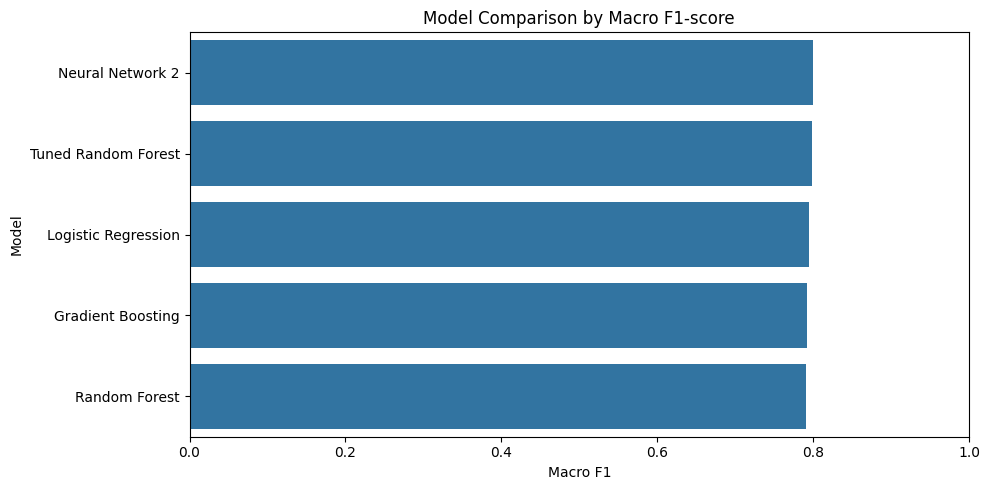

Best overall model: Neural Network 2


In [17]:
results = []

# Evaluate traditional models
for model_name, model in trained_models.items():
    predictions = model.predict(X_test_processed)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, predictions,
        average="macro",
        zero_division=0
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1
    })

# Add the selected neural network
precision, recall, f1, _ = precision_recall_fscore_support(
    y_test, dl_predictions,
    average="macro",
    zero_division=0
)

results.append({
    "Model": best_dl_name,
    "Accuracy": accuracy_score(y_test, dl_predictions),
    "Macro Precision": precision,
    "Macro Recall": recall,
    "Macro F1": f1
})

results_df = pd.DataFrame(results).sort_values(
    "Macro F1", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

# Plot the comparison
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Macro F1", y="Model")
plt.title("Model Comparison by Macro F1-score")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

print("Best overall model:", results_df.iloc[0]["Model"])

## 16. ROC Curves and ROC-AUC

I used ROC curves and ROC-AUC scores to compare how well the models distinguish between the three productivity classes. I used the one-vs-rest method, which compares each class against the other two classes. A higher ROC-AUC score indicates better class separation.

,Model,Macro ROC-AUC
4,Neural Network 2,0.9327
3,Tuned Random Forest,0.9310
2,Gradient Boosting,0.9275
1,Random Forest,0.9259
0,Logistic Regression,0.9249


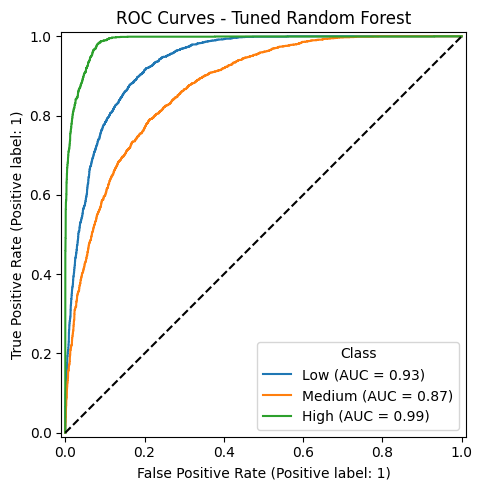

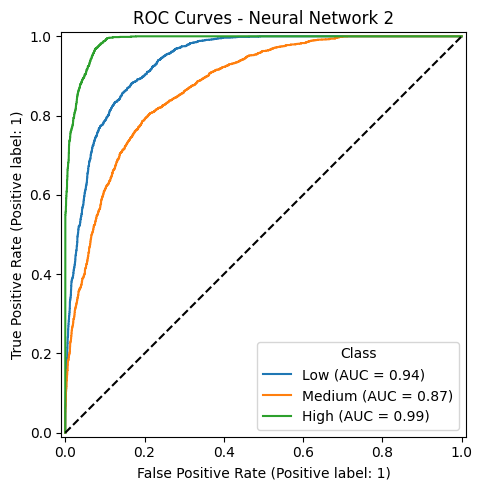

In [18]:
# Convert test labels to binary format
y_test_binary = label_binarize(y_test, classes=class_names)

probability_models = {}
roc_results = []

# Get probabilities from traditional models
for name, model in trained_models.items():
    probabilities = model.predict_proba(X_test_processed)

    # Match probability columns to Low, Medium, High
    aligned_probabilities = np.zeros(
        (len(y_test), len(class_names))
    )

    for i, class_name in enumerate(model.classes_):
        class_index = class_names.index(class_name)
        aligned_probabilities[:, class_index] = probabilities[:, i]

    probability_models[name] = aligned_probabilities

# Add neural network probabilities
probability_models[best_dl_name] = dl_probabilities

# Calculate ROC-AUC scores
for name, probabilities in probability_models.items():
    score = roc_auc_score(
        y_test_binary,
        probabilities,
        average="macro"
    )

    roc_results.append({
        "Model": name,
        "Macro ROC-AUC": score
    })

roc_auc_df = pd.DataFrame(roc_results).sort_values(
    "Macro ROC-AUC",
    ascending=False
)

display(roc_auc_df.round(4))


# Compare the best traditional model with the neural network
best_traditional = results_df[
    results_df["Model"] != best_dl_name
].sort_values("Macro F1", ascending=False).iloc[0]["Model"]

models_to_plot = [best_traditional, best_dl_name]

# Plot ROC curves
for name in models_to_plot:
    fig, ax = plt.subplots(figsize=(6, 5))

    for i, class_name in enumerate(class_names):
        RocCurveDisplay.from_predictions(
            y_test_binary[:, i],
            probability_models[name][:, i],
            name=class_name,
            ax=ax
        )

    ax.plot([0, 1], [0, 1], "k--")
    ax.set_title(f"ROC Curves - {name}")
    ax.legend(title="Class")

    plt.tight_layout()
    plt.show()

## 17. Traditional Model Learning Curve

I used a learning curve to observe how the best traditional model performs with different amounts of training data. The results are based on cross-validation using the training set.

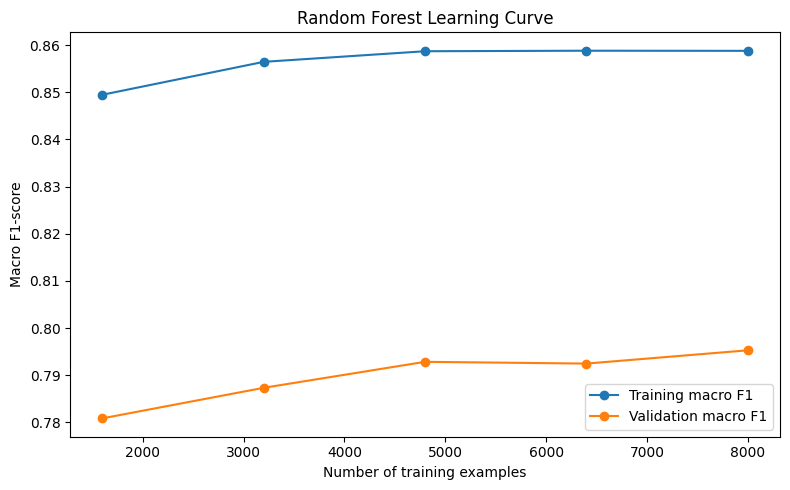

In [19]:
# Use a sample of the training data to keep this experiment manageable
sample_size = min(12000, len(y_train))
rng = np.random.RandomState(42)
sample_indices = rng.choice(len(y_train), size=sample_size, replace=False)

X_curve = X_train_processed[sample_indices]
y_curve = y_train.iloc[sample_indices]

curve_sizes, train_scores, validation_scores = learning_curve(
    estimator=best_rf,
    X=X_curve,
    y=y_curve,
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=3,
    scoring="f1_macro",
    n_jobs=-1
)

plt.figure(figsize=(8, 5))
plt.plot(curve_sizes, train_scores.mean(axis=1), marker="o", label="Training macro F1")
plt.plot(curve_sizes, validation_scores.mean(axis=1), marker="o", label="Validation macro F1")
plt.xlabel("Number of training examples")
plt.ylabel("Macro F1-score")
plt.title("Random Forest Learning Curve")
plt.legend()
plt.tight_layout()
plt.show()

## 18. Feature Importance

I used Random Forest feature importance to identify the features that contributed most to the model’s predictions.

,Feature,Importance
59,categorical__CropCategory_Maize,0.129290
50,categorical__CropCategory_Bush bean,0.126470
49,categorical__CropCategory_Banana for beer,0.111229
53,categorical__CropCategory_Cooking banana,0.084739
2,numeric__Crop_Area_ha,0.062343
1,numeric__Plot_area_ha,0.059426
52,categorical__CropCategory_Climbing bean,0.051008
54,categorical__CropCategory_Dessert banana,0.045195
0,numeric__s1q9,0.044939
51,categorical__CropCategory_Cassava,0.040966


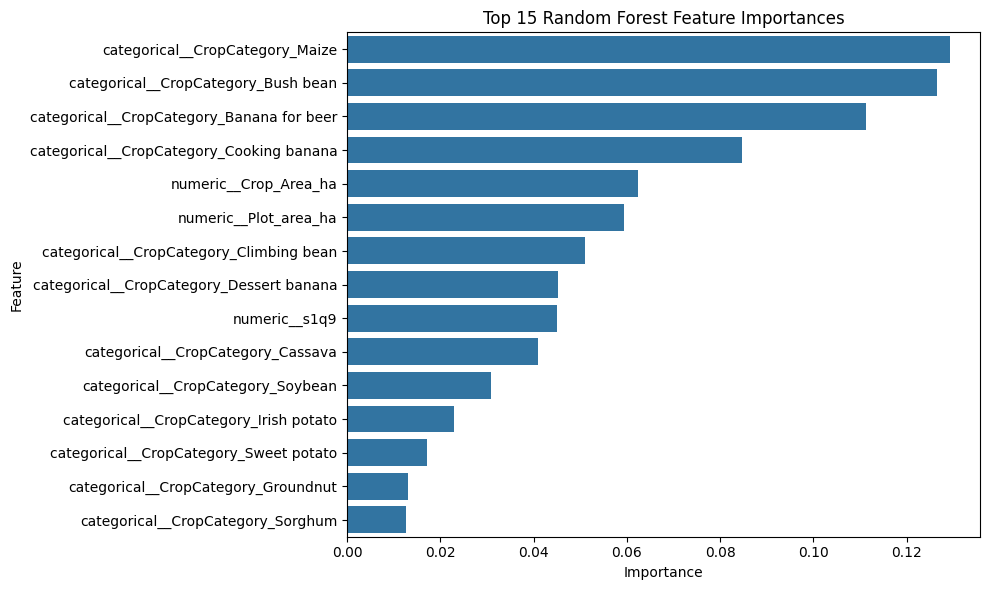

In [20]:
feature_names = preprocessor.get_feature_names_out()
importances = best_rf.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False).head(15)

display(importance_df)

plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x="Importance", y="Feature")
plt.title("Top 15 Random Forest Feature Importances")
plt.tight_layout()
plt.show()

## 19. Saving the Best Models and Preprocessing Steps

I saved the best traditional model, the selected neural network, and the preprocessing steps used during training.

In [21]:
# Select the best traditional model using macro F1 from the test comparison
traditional_only = results_df[
    results_df["Model"] != best_dl_name
].sort_values("Macro F1", ascending=False)

best_traditional_name = traditional_only.iloc[0]["Model"]
best_traditional_model = trained_models[best_traditional_name]

os.makedirs("/content/saved_models", exist_ok=True)

joblib.dump(best_traditional_model, "/content/saved_models/best_traditional_model.joblib")
joblib.dump(preprocessor, "/content/saved_models/preprocessor.joblib")
selected_model.save("/content/saved_models/agricultural_productivity_model.keras")

print("Best traditional model:", best_traditional_name)
print("Saved files:")
print("- /content/saved_models/best_traditional_model.joblib")
print("- /content/saved_models/preprocessor.joblib")
print("- /content/saved_models/agricultural_productivity_model.keras")

Best traditional model: Tuned Random Forest
Saved files:
- /content/saved_models/best_traditional_model.joblib
- /content/saved_models/preprocessor.joblib
- /content/saved_models/agricultural_productivity_model.keras


## 20. Downloading the Saved Models

I saved the trained models in the Colab session and downloaded them to upload to the required Google Drive folder.

In [22]:
import shutil

shutil.make_archive(
    "/content/saved_models",
    "zip",
    "/content/saved_models"
)

from google.colab import files
files.download("/content/saved_models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 21. Conclusion and Limitations

### Conclusion

In this project, I compared traditional machine learning models and a deep learning model to classify agricultural productivity levels in Rwanda. I used the Rwanda Seasonal Agricultural Survey 2025 dataset and grouped the yield values into three classes: Low, Medium, and High productivity.

The results showed that Neural Network 2 had the best performance, with a test accuracy of **80.36%** and a macro F1-score of **0.8003**. The Tuned Random Forest was the second-best model, with a test accuracy of **80.14%** and a macro F1-score of **0.7984**. The results show that the neural network performed slightly better than the traditional models.

The models performed better when predicting the High productivity class, while the Medium class was more difficult to predict. Overall, this project showed that machine learning can be used to find patterns in agricultural productivity data, but more improvements may be needed to get better results.

### Limitations

- The dataset was reduced from 34,369 to 29,938 rows because records with missing, invalid, or non-positive yield values were removed.
- The productivity classes were created using yield tertiles, so they are not official agricultural productivity categories.
- The models used only selected features, meaning that some factors affecting productivity may not have been included.
- The Medium productivity class was harder to predict compared to the Low and High classes.
- The models were tested using one dataset and one train-test split, so the results may change when using data from other seasons or years.
- The results show relationships in this dataset, but they do not mean that the selected features directly cause changes in productivity.

## 22. Reproducibility Notes

- Dataset: Rwanda Seasonal Agricultural Survey 2025, Season A production file. https://www.microdata.statistics.gov.rw/index.php/catalog/124
- Random seed: 42.
- Test split: 20%, stratified by productivity class.
- Traditional model tuning: 3-fold cross-validation on the training data.
- Deep learning: TensorFlow/Keras with `tf.data`, validation data, and early stopping.